# 07 — Final CatBoost Model and Kaggle Submission Review

**Objective:** Verify the final 15-model CatBoost ensemble and its Kaggle submission before uploading. The selected model uses the original 39-feature dataset. We average five fold-model predictions for each of three seeds (`42`, `123`, `2026`).

Run `python -m src.predict` **from the repository root** before running this notebook. All plots and tables below come from the generated reports. No model is trained inside this notebook.

## 1. Load the final artifacts

This is a read-only review. The submission script saves all reports under `data/processed/final/`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
REPORT_DIR = ROOT / 'data' / 'processed' / 'final'
required = ['run_config.json', 'catboost_final.csv', 'cross_validation_summary.csv',
            'fold_metrics.csv', 'oof_predictions.csv', 'test_predictions.csv']
missing = [name for name in required if not (REPORT_DIR / name).exists()]
if missing:
    raise FileNotFoundError(f'Missing {missing} in {REPORT_DIR}. Run python -m src.predict from repo root.')

config = json.loads((REPORT_DIR / 'run_config.json').read_text())
summary = pd.read_csv(REPORT_DIR / 'cross_validation_summary.csv')
folds = pd.read_csv(REPORT_DIR / 'fold_metrics.csv')
oof = pd.read_csv(REPORT_DIR / 'oof_predictions.csv', dtype={'account.id': 'string'})
test_preds = pd.read_csv(REPORT_DIR / 'test_predictions.csv', dtype={'ID': 'string'})
submission = pd.read_csv(REPORT_DIR / 'catboost_final.csv', dtype={'ID': 'string'})
print('Selected model:', config['selected_model'])
print('Features:', config['predictive_features'], '| Trained models:', config['trained_models'])
print('Seeds:', config['seeds'], '| Folds per seed:', config['folds_per_seed'])
print('Training patrons:', config['train_accounts'], '| Kaggle patrons:', config['test_accounts'])

Selected model: catboost_default
Features: 39 | Trained models: 15
Seeds: [42, 123, 2026] | Folds per seed: 5
Training patrons: 6941 | Kaggle patrons: 2975


## 2. Cross-validation results

The three seed scores are directly comparable to our model-optimization notebook. The **averaged OOF** score is based on the mean prediction for each patron across seeds; it is a validation diagnostic, not a new untouched test result.

,candidate,seed,oof_auc,oof_average_precision
0,catboost_seed_42,42,0.97139,0.84040
1,catboost_seed_123,123,0.97191,0.83545
2,catboost_seed_2026,2026,0.96835,0.84195
3,catboost_15_model_mean,ensemble,0.97180,0.83956


Mean seed AUROC: 0.97055
Std seed AUROC: 0.00192
Averaged OOF AUROC: 0.97180
Averaged OOF AP: 0.83956


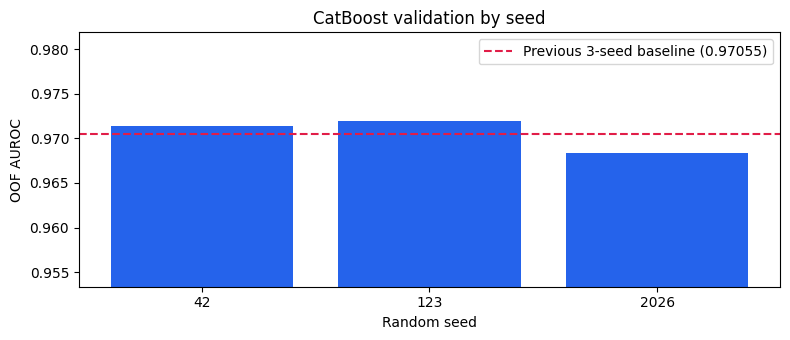

In [2]:
display(summary.round(5))
seed_rows = summary[summary['seed'].astype(str) != 'ensemble'].copy()
print(f"Mean seed AUROC: {seed_rows['oof_auc'].mean():.5f}")
print(f"Std seed AUROC: {seed_rows['oof_auc'].std(ddof=1):.5f}")
print(f"Averaged OOF AUROC: {roc_auc_score(oof['label'], oof['pred_mean']):.5f}")
print(f"Averaged OOF AP: {average_precision_score(oof['label'], oof['pred_mean']):.5f}")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(seed_rows['seed'].astype(str), seed_rows['oof_auc'], color='#2563eb')
ax.axhline(0.97055, color='#e11d48', linestyle='--', label='Previous 3-seed baseline (0.97055)')
ax.set_ylim(max(0.94, seed_rows['oof_auc'].min() - 0.015), min(1., seed_rows['oof_auc'].max() + 0.01))
ax.set_xlabel('Random seed'); ax.set_ylabel('OOF AUROC'); ax.set_title('CatBoost validation by seed')
ax.legend(); plt.tight_layout(); plt.show()

## 3. Fold-level stability

Check whether any one fold is materially worse than the others. Variation is expected because only a small fraction of patrons purchase subscriptions.

In [3]:
display(folds[['seed', 'fold', 'validation_accounts', 'validation_buyers', 'roc_auc', 'average_precision']].round(4))
print('Fold AUROC range:', round(folds['roc_auc'].min(), 5), 'to', round(folds['roc_auc'].max(), 5))

,seed,fold,validation_accounts,validation_buyers,roc_auc,average_precision
0,42,1,1389,67,0.9699,0.8352
1,42,2,1388,66,0.9727,0.8560
2,42,3,1388,66,0.9810,0.8860
3,42,4,1388,66,0.9622,0.8046
4,42,5,1388,67,0.9783,0.8724
5,123,1,1389,67,0.9735,0.8705
6,123,2,1388,66,0.9634,0.8193
7,123,3,1388,66,0.9750,0.8644
8,123,4,1388,66,0.9732,0.8165
9,123,5,1388,67,0.9793,0.8575


Fold AUROC range: 0.95792 to 0.98694


## 4. Feature importance

These are CatBoost's built-in feature importance values averaged across seeds. They describe which inputs the trained model uses, not necessarily causal effects.

,feature,importance_mean,importance_std
0,zip_lat,10.878,1.616
1,zip_long,7.783,1.069
2,sub_active_2013,7.406,0.997
3,sub_last_year,6.725,0.208
4,sub_recency_seasons,6.460,1.761
5,billing_zip,5.304,1.250
6,sub_seasons_last_2,4.408,0.632
7,sub_last_package,4.112,0.613
8,billing_city,3.860,1.044
9,sub_last_location,3.495,0.185


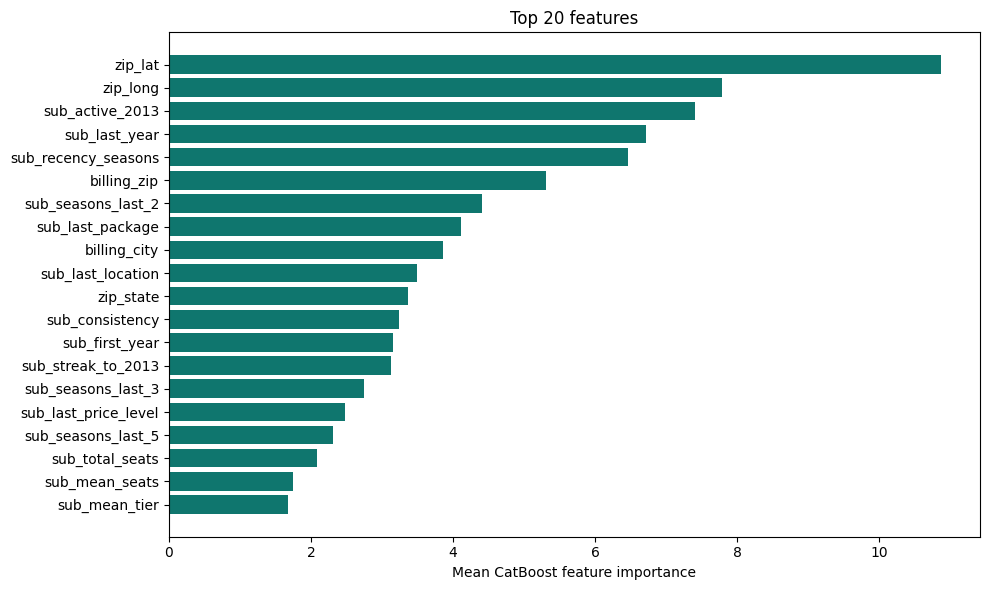

In [4]:
importance_path = REPORT_DIR / 'feature_importance.csv'
if importance_path.exists():
    importance = pd.read_csv(importance_path).sort_values('importance_mean', ascending=False)
    display(importance.head(20).round(3))
    top = importance.head(20).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top['feature'], top['importance_mean'], color='#0f766e')
    ax.set_xlabel('Mean CatBoost feature importance'); ax.set_title('Top 20 features')
    plt.tight_layout(); plt.show()
else:
    print('Feature importance file was not produced by the model.')

## 5. Discrimination on labeled patrons

The ROC and PR curves use **out-of-fold** predictions only. Average precision is especially informative because subscription purchases are rare.

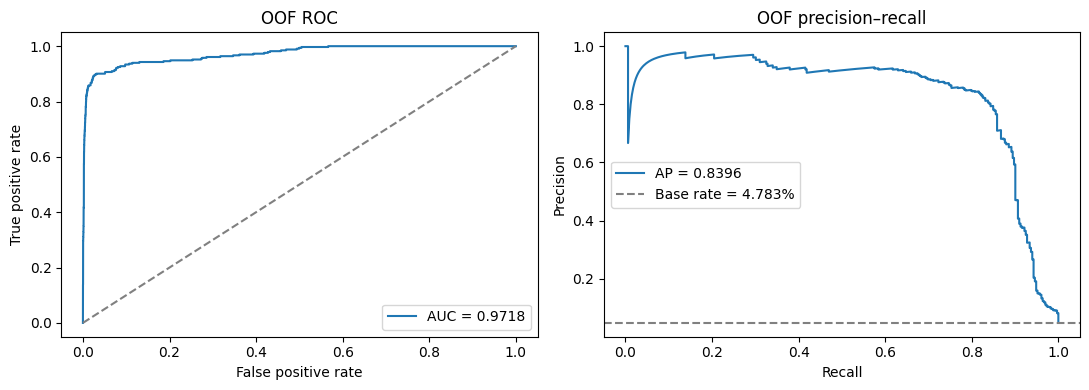

In [5]:
y = oof['label'].to_numpy(dtype=int)
p = oof['pred_mean'].to_numpy(dtype=float)
fpr, tpr, _ = roc_curve(y, p)
precision, recall, _ = precision_recall_curve(y, p)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y, p):.4f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='OOF ROC')
axes[0].legend()
axes[1].plot(recall, precision, label=f'AP = {average_precision_score(y, p):.4f}')
axes[1].axhline(y.mean(), linestyle='--', color='gray', label=f'Base rate = {y.mean():.3%}')
axes[1].set(xlabel='Recall', ylabel='Precision', title='OOF precision–recall')
axes[1].legend(); plt.tight_layout(); plt.show()

## 6. Inspect the Kaggle test probabilities

We inspect the distribution and compare it with OOF probabilities. The **sum of probabilities is not a validated subscriber-count forecast** unless probability calibration has been established; AUROC only measures ranking.

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
pred_mean,2975.0,0.04902,0.18675,0.0003,0.00049,0.00094,0.00124,0.00167,0.0049,0.0076,0.01611,0.31408,0.97248,0.99062


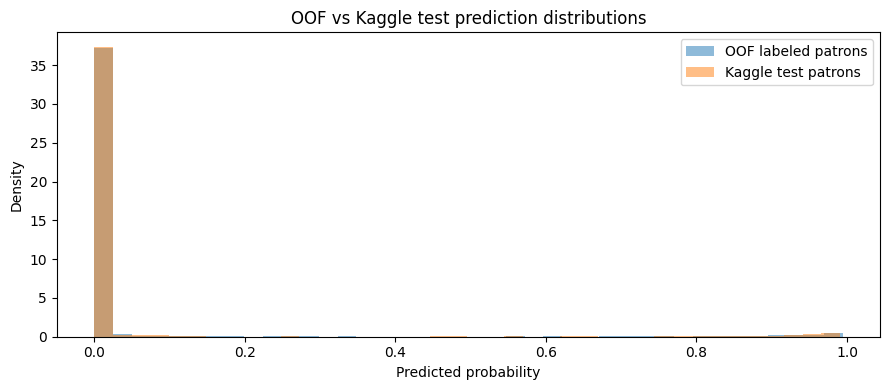

Illustrative probability cutoffs (not submission thresholds):
  p >= 0.05: 202 test accounts
  p >= 0.10: 177 test accounts
  p >= 0.25: 154 test accounts
  p >= 0.50: 137 test accounts
  p >= 0.75: 115 test accounts


In [6]:
display(test_preds[['pred_mean']].describe(percentiles=[.01, .05, .1, .25, .5, .75, .9, .95, .99]).T.round(5))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(oof['pred_mean'], bins=40, alpha=0.5, density=True, label='OOF labeled patrons')
ax.hist(test_preds['pred_mean'], bins=40, alpha=0.5, density=True, label='Kaggle test patrons')
ax.set(xlabel='Predicted probability', ylabel='Density', title='OOF vs Kaggle test prediction distributions')
ax.legend(); plt.tight_layout(); plt.show()
print('Illustrative probability cutoffs (not submission thresholds):')
for threshold in [0.05, 0.1, 0.25, 0.5, 0.75]:
    print(f'  p >= {threshold:.2f}: {(test_preds["pred_mean"] >= threshold).sum():,} test accounts')

## 7. Submission integrity verification

This is a **blocking check**. The Kaggle CSV must have `ID,Predicted`, exactly one row per hidden test account, IDs identical to the official template in the **same order**, and finite probabilities between 0 and 1.

In [7]:
sample_path = ROOT / 'data' / 'raw' / 'sample_submission.csv'
sample = pd.read_csv(sample_path, dtype={'ID': 'string'})
assert submission.columns.tolist() == sample.columns.tolist() == ['ID', 'Predicted']
assert len(submission) == len(sample) == len(test_preds) == config['test_accounts']
assert submission['ID'].notna().all() and submission['ID'].is_unique
assert test_preds['ID'].notna().all() and test_preds['ID'].is_unique
assert submission['ID'].tolist() == sample['ID'].tolist()
assert set(submission['ID']) == set(test_preds['ID'])
assert np.isfinite(submission['Predicted']).all()
assert submission['Predicted'].between(0, 1).all()
reference = test_preds.set_index('ID')['pred_mean'].reindex(submission['ID']).to_numpy()
assert np.allclose(submission['Predicted'], reference, rtol=1e-9, atol=1e-10)
assert oof['account.id'].is_unique and oof['label'].isin([0, 1]).all()
assert len(oof) == config['train_accounts']
print('PASS — sample order, account ID set, row counts, finite probabilities, and exact prediction alignment.')
print('Submission file:', REPORT_DIR / 'catboost_final.csv')
display(submission.head(10))

PASS — sample order, account ID set, row counts, finite probabilities, and exact prediction alignment.
Submission file: /home/konurnordberg/aipi/520-models/kaggle-competition/orchestra-subscription-prediction/data/processed/final/catboost_final.csv


,ID,Predicted
0,001i000000NuQ6Y,0.009076
1,001i000000NuQXz,0.041341
2,001i000000NuRDC,0.019421
3,001i000000NuQeg,0.005401
4,001i000000NuOQc,0.021139
5,001i000000NuPjO,0.006588
6,001i000000NuP34,0.001874
7,001i000000NuS8R,0.001671
8,001i000000NuQTS,0.001196
9,001i000000NuOFe,0.001993
